# Digital Multimeter Examples

## Initial Setup
Import the digital multimeter class from `inspy.instrument.digitalmultimeter`. The device connection can be managed by using the `connect()` and `disconnect()` methods. However, the use of context managers (see <a href="#section">trace example</a>) is recommended.

In [1]:
import matplotlib.pyplot as plt

from inspy.instrument.digitalmultimeter import DmmKeysight34465A

ADDRESS = "USB0::10893::257::MY57500323::0::INSTR"
dmm: DmmKeysight34465A = DmmKeysight34465A(ADDRESS)
dmm.connect()
dmm_id = dmm.get_id()
print(dmm_id)

Keysight Technologies,34465A,MY57500323,A.02.14-02.40-02.14-00.49-03-01


## Simple Measurements
Single measurements can be made using the measure methods.

In [2]:
voltage = dmm.measure_voltage()
current = dmm.measure_current()
voltage_ac = dmm.measure_voltage_ac()
current_ac = dmm.measure_current_ac()
resistance = dmm.measure_resistance()
resistance_four_wire = dmm.measure_resistance_four_wire()
continuity = dmm.measure_continuity()
frequency = dmm.measure_frequency()
period = dmm.measure_period()

print(f"Voltage: {voltage} V")
print(f"Current: {current} A")
print(f"AC Voltage: {voltage_ac} V")
print(f"AC Current: {current_ac} A")
print(f"Resistance: {resistance} Ohms")
print(f"4-Wire Resistance: {resistance_four_wire} Ohms")
print(f"Continuity: {continuity}")
print(f"Frequency: {frequency}")
print(f"Period: {period}")
dmm.disconnect()

Voltage: 1.17625601e-05 V
Current: 3.16225072e-12 A
AC Voltage: 0.00119330846 V
AC Current: 0.0 A
Resistance: 9.9e+37 Ohms
4-Wire Resistance: 789.106695 Ohms
Continuity: True
Frequency: 99.9656529
Period: 0.0100052345


## Trace Example <a id='section'></a>
Trace functions include: `'VOLT'`, `'VOLT:AC'`, `'CURR'`, `'CURR:AC'`,`'RES'`, `'FRES'`, `'TEMP'`, `'FREQ'`, `'PER'`, `'DIOD'`, `'CONT'`, `'CAP'`. Note averaging time can only be set for `'VOLT'`, `'CURR'`, `'RES'`, `'FRES'`, `'TEMP'`.

In [3]:
with DmmKeysight34465A(ADDRESS) as dmm:
    # Set the trace function you want to measure
    dmm.set_sampling_measurement_mode(function="VOLT")

    # Optional: Configure averaging time and measurement range and trigger delay.
    # See measurement section below.
    dmm.set_measurement_range(measurement_range=1)
    dmm.set_averaging_time(averaging_time=0.01)

    # Configure sampling
    dmm.set_sample_points(sample_points=100)
    dmm.set_measurement_range(measurement_range=1)
    dmm.set_sample_interval(
        sample_interval=0.03
    )  # Must be at least 2.1x bigger than averaging time?

    # Configure trigger
    dmm.set_trigger_immediate()
    dmm.set_trigger_delay(trigger_delay=0.01)
    dmm.set_wait_for_trigger()  # Set state to wait-for-trigger

    # Read samples
    samples = dmm.get_samples(
        polling_cycle=1
    )  # Blocks code, waits for trigger event and measurements to complete.
    # Sets polling cycle to 1 second.
    print(f"Sampled Values:{samples}")

    # Reset Instrument to factory default.
    dmm.reset()

Sampled Values:[-0.000174865096, 0.000189855769, -0.000160194402, 0.000166605493, -0.000140659566, 0.000146773698, -0.000122314868, 0.000126154617, -9.79458165e-05, 0.000105457267, -7.23774188e-05, 8.40969392e-05, -5.56556361e-05, 6.23982162e-05, -2.82502364e-05, 4.05728828e-05, -9.15508396e-06, 1.91112665e-05, 5.81026701e-06, -4.8273098e-06, 2.87520741e-05, -2.25205397e-05, 4.86828553e-05, -5.37564799e-05, 6.85837104e-05, -6.82361073e-05, 9.37124246e-05, -9.03100575e-05, 0.000118610938, -0.000119216366, 0.000143131922, -0.000129066656, 0.00016075379, -0.000154674188, 0.000179429977, -0.000172809403, 0.000196957462, -0.000199558731, 0.000220764824, -0.000220559946, 0.000240382533, -0.000235513787, 0.00025604309, -0.000261367633, 0.000277799363, -0.000278130852, 0.000299311623, -0.000301735637, 0.000322071572, -0.000318112119, 0.000339944358, -0.000338959099, 0.000362170241, -0.000360940969, 0.000383054053, -0.000381058213, 0.000402139998, -0.000396196214, 0.000426852049, -0.00041945339

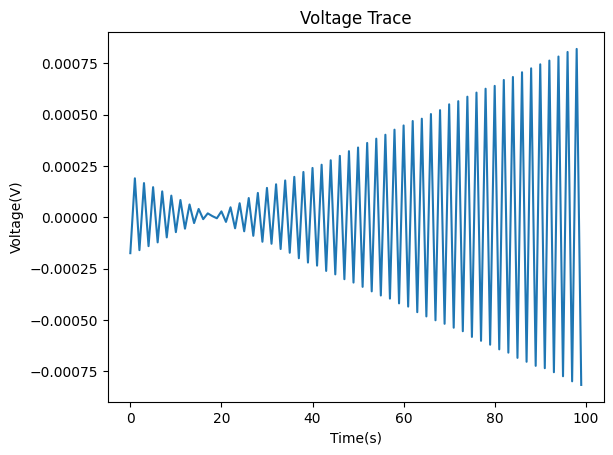

In [4]:
# Plot Function
plt.plot(samples)
plt.title("Voltage Trace")
plt.xlabel("Time(s)")
plt.ylabel("Voltage(V)")
plt.show()

## Trigger sources explained

In [5]:
dmm.connect()

### Immediate
Triggers immediately after the instrument is put into wait-for-trigger state.

In [6]:
dmm.set_trigger_immediate()
dmm.set_wait_for_trigger()  # Triggers straight away.

### External
Triggers when a TTL pulse is received on the Ext-Trig input.

In [7]:
dmm.set_trigger_external(pos_edge=False)  # Negative slope triggering
dmm.set_wait_for_trigger()

### Bus
Triggers when a *TRG command is received.

In [8]:
dmm.set_trigger_bus()
dmm.set_wait_for_trigger()
dmm.trigger_now()

### Level
Triggers on a level on the input signal.

In [9]:
dmm.set_trigger_internal_level(trigger_level=3, pos_edge=True)
dmm.set_wait_for_trigger()

In [10]:
dmm.disconnect()

## Measurement time explained

The first sample starts one trigger-delay time after the trigger. However, the second sample
starts one sample interval after the start of the first sample, and so on:

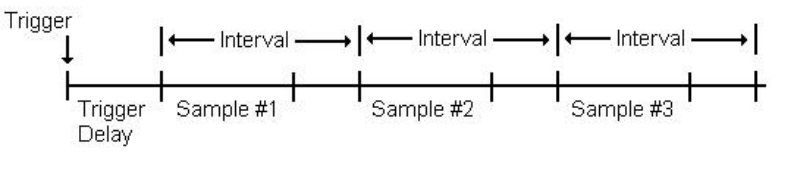

In [11]:
from IPython.display import Image

Image("sampling.png")

The minimum sample time is measurement dependent. It depends on such things as the integration time (`set_averaging_time()`),
autozero on or off, autorange on or off, and the measurement range. Basically, MIN is automatically
determined so that the sample interval is always greater than the sampling time (see above illustration). Use `dmm.get_sample_interval_min()`/`dmm.set_sample_interval_min()` to determine the recommended interval for the current
measurement configuration.